# Taller 2 — Persona 3: Entrenamiento y experimentación DQN
**Universidad de La Sabana · Maestría en Inteligencia Artificial**  
**Estudiante:** Adrián Trochez  
**Entorno:** `LunarLander-v3` · **Algoritmo:** DQN en PyTorch

Este notebook **reutiliza la arquitectura 8→128→128→4, Replay Buffer, ε-greedy y Target Network** de la Persona 2, pero organiza experimentos con semillas, registros, evaluación y guardado de modelos. **Los resultados deben ejecutarse; no se presuponen.**

**Procedimiento:** ejecuta las celdas de arriba hacia abajo. El entrenamiento puede tardar bastante en Colab; comienza con el ensayo corto. Se recomienda ejecutar en CPU inicialmente (Entorno de ejecución → Cambiar tipo de entorno de ejecución).

> **Nota de revisión (12 de octubre de 2026).** Este notebook se ejecutó en Google Colab y las salidas que se muestran son las de esa ejecución. Después se hicieron tres ajustes al código, sin cambiar el método ni los resultados:
>
> 1. Fuera de Colab los archivos se guardan en `resultados/persona_3_local/` en lugar de Google Drive.
> 2. El entrenamiento de las tres semillas quedó en una sola celda que evalúa con `evaluate_model`. En la ejecución original se hizo en dos partes, porque la primera llamaba a una función que todavía no estaba definida.
> 3. Se quitaron las celdas de recuperación que solo servían para continuar después de ese error.
>
> Con estos ajustes el notebook se ejecuta completo de principio a fin. Al repetirlo en otra máquina los números cambian aunque las semillas sean las mismas; el README explica por qué.

## 1. Dependencias y persistencia

In [ ]:
%pip -q install "gymnasium[box2d]" torch pandas matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 37.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 29.8 MB/s eta 0:00:00


In [ ]:
# En Colab los archivos se guardan en Google Drive; fuera de Colab, en una carpeta del repositorio
from pathlib import Path
try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT = Path('/content/drive/MyDrive/Taller_2_DQN_Adrian')
except ImportError:
    OUT = Path('resultados/persona_3_local')
OUT.mkdir(parents=True, exist_ok=True)
print('Archivos persistentes en:', OUT)

Mounted at /content/drive
Archivos persistentes en: /content/drive/MyDrive/Taller_2_DQN_Adrian


## 2. Entorno, semillas y arquitectura (compatible con Persona 2)

In [ ]:
import os, time, random, json, copy
from collections import deque
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import gymnasium as gym
import torch
from torch import nn, optim

# Para esta red pequeña, CPU suele ser suficiente; GPU también funciona.
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ENV_ID = 'LunarLander-v3'
probe = gym.make(ENV_ID)
STATE_SIZE = probe.observation_space.shape[0]
ACTION_SIZE = probe.action_space.n
print('Dispositivo:', DEVICE, 'Observaciones:', probe.observation_space, 'Acciones:', probe.action_space)
assert STATE_SIZE == 8 and ACTION_SIZE == 4
probe.close()

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

class DQN(nn.Module):
    def __init__(self, state_size=STATE_SIZE, action_size=ACTION_SIZE):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(state_size,128),nn.ReLU(),
                                     nn.Linear(128,128),nn.ReLU(),nn.Linear(128,action_size))
    def forward(self,x): return self.network(x)

class ReplayBuffer:
    def __init__(self, capacity=100000): self.buffer=deque(maxlen=capacity)
    def push(self, s,a,r,ns,terminated):
        self.buffer.append((np.asarray(s,dtype=np.float32).copy(),int(a),float(r),
                            np.asarray(ns,dtype=np.float32).copy(),float(terminated)))
    def sample(self,n):
        s,a,r,ns,d=zip(*random.sample(self.buffer,n))
        return (np.asarray(s,dtype=np.float32),np.asarray(a,dtype=np.int64),
                np.asarray(r,dtype=np.float32),np.asarray(ns,dtype=np.float32),
                np.asarray(d,dtype=np.float32))
    def __len__(self): return len(self.buffer)

print(DQN())

Dispositivo: cpu Observaciones: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32) Acciones: Discrete(4)
DQN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=4, bias=True)
  )
)


## 3. Entrenamiento DQN
La red Q se actualiza con muestras del Replay Buffer. La red objetivo se sincroniza cada cierto número de episodios. En la ecuación de Bellman se anula el *bootstrap* solo cuando `terminated=True`; una truncación finaliza el episodio, pero no equivale necesariamente a un estado terminal del MDP. Esto es una **corrección técnica explícita** respecto al notebook original.

In [ ]:
def train_experiment(name, seed, episodes=1000, lr=0.001, batch_size=64,
                     gamma=0.99, epsilon_decay=0.995, epsilon_min=0.01,
                     target_update=10, capacity=100000, log_every=25):
    seed_everything(seed)
    env = gym.make(ENV_ID)
    env.action_space.seed(seed)
    online = DQN().to(DEVICE)
    target = DQN().to(DEVICE)
    target.load_state_dict(online.state_dict()); target.eval()
    optimizer = optim.Adam(online.parameters(), lr=lr)
    loss_fn = nn.MSELoss() # Consistente con Persona 2
    replay = ReplayBuffer(capacity)
    epsilon = 1.0
    rows=[]
    start=time.time()
    for ep in range(1,episodes+1):
        state,_=env.reset(seed=seed+ep)
        ep_reward=0.; losses=[]; steps=0
        terminated=truncated=False
        while not (terminated or truncated):
            if random.random()<epsilon:
                action=env.action_space.sample()
            else:
                with torch.no_grad():
                    st=torch.as_tensor(state,dtype=torch.float32,device=DEVICE).unsqueeze(0)
                    action=int(online(st).argmax(dim=1).item())
            next_state,reward,terminated,truncated,_=env.step(action)
            replay.push(state,action,reward,next_state,terminated)
            if len(replay)>=batch_size:
                s,a,r,ns,d=replay.sample(batch_size)
                s=torch.as_tensor(s,device=DEVICE)
                a=torch.as_tensor(a,device=DEVICE).unsqueeze(1)
                r=torch.as_tensor(r,device=DEVICE).unsqueeze(1)
                ns=torch.as_tensor(ns,device=DEVICE)
                d=torch.as_tensor(d,device=DEVICE).unsqueeze(1)
                q=online(s).gather(1,a)
                with torch.no_grad():
                    y=r+gamma*target(ns).max(dim=1,keepdim=True).values*(1-d)
                loss=loss_fn(q,y)
                optimizer.zero_grad(); loss.backward(); optimizer.step()
                losses.append(float(loss.item()))
            state=next_state
            ep_reward+=float(reward); steps+=1
        epsilon=max(epsilon_min,epsilon*epsilon_decay)
        if ep%target_update==0: target.load_state_dict(online.state_dict())
        rows.append({'experimento':name,'semilla':seed,'episodio':ep,'recompensa':ep_reward,
                     'perdida_media':float(np.mean(losses)) if losses else np.nan,
                     'epsilon':epsilon,'pasos':steps})
        if ep%log_every==0:
            print(f'{name} semilla={seed} episodio={ep}/{episodes} '
                  f'promedio_ultimos_25={np.mean([x["recompensa"] for x in rows[-25:]]):.1f} '
                  f'epsilon={epsilon:.3f} tiempo={time.time()-start:.0f}s')
    env.close()
    return online, pd.DataFrame(rows), time.time()-start

def evaluate_model(model, seeds=range(10000,10100)):
    env=gym.make(ENV_ID)
    model.eval(); scores=[]
    for seed in seeds:
        state,_=env.reset(seed=int(seed))
        terminated=truncated=False; total=0.
        while not (terminated or truncated):
            with torch.no_grad():
                st=torch.as_tensor(state,dtype=torch.float32,device=DEVICE).unsqueeze(0)
                action=int(model(st).argmax(dim=1).item())
            state,reward,terminated,truncated,_=env.step(action)
            total+=float(reward)
        scores.append(total)
    env.close()
    return np.asarray(scores,dtype=float)

## 4. Ensayo corto de funcionamiento (NO constituye resultado final)

In [ ]:
modelo_test, historial_test, segundos_test = train_experiment(
    name='prueba_10_episodios', seed=42, episodes=10, log_every=5)
print(historial_test.tail(3).to_string(index=False))
print('Tiempo de prueba (s):', round(segundos_test,1))

prueba_10_episodios semilla=42 episodio=5/10 promedio_ultimos_25=-149.4 epsilon=0.975 tiempo=1s
prueba_10_episodios semilla=42 episodio=10/10 promedio_ultimos_25=-146.9 epsilon=0.951 tiempo=2s
        experimento  semilla  episodio  recompensa  perdida_media  epsilon  pasos
prueba_10_episodios       42         8 -111.474552      48.724295 0.960693     72
prueba_10_episodios       42         9 -256.163628      45.119669 0.955890    140
prueba_10_episodios       42        10 -107.038780      59.636586 0.951110     65
Tiempo de prueba (s): 1.7


## 5. Experimentos comparativos
Los siguientes son **tres ensayos propuestos**, con la misma arquitectura de Persona 2. Se cambia solamente la tasa de aprendizaje para aislar su efecto. El baseline usa los hiperparámetros originales. **Los 1.000 episodios y las tres semillas por configuración pueden tardar bastante.** Para una prueba preliminar usa `EPISODES=100` y `SEEDS=[42]`, pero para el informe final aumenta la duración y las repeticiones.

In [ ]:
EPISODES = 300    # Cambia a 100 para prueba rápida; luego vuelve a 1000
SEEDS = [42]  # Para prueba rápida usa [42]
CONFIGS = [
    {'name':'A_baseline','lr':0.001},
    {'name':'B_lr_0005','lr':0.0005},
    {'name':'C_lr_0001','lr':0.0001},
]
EVAL_SEEDS = list(range(10000,10100))  # Mismas 100 semillas para todos
print('Total entrenamientos:',len(CONFIGS)*len(SEEDS))

Total entrenamientos: 3


In [ ]:
all_histories=[]; all_evaluations=[]; summaries=[]
for config in CONFIGS:
    for seed in SEEDS:
        tag=f'{config["name"]}_seed{seed}'
        print('\nENTRENANDO',tag)
        model,hist,elapsed=train_experiment(config['name'],seed,episodes=EPISODES,
                                            lr=config['lr'])
        hist.to_csv(OUT/f'historial_{tag}.csv',index=False)
        torch.save({'state_dict':model.state_dict(), 'architecture':[8,128,128,4],
                    'config':config,'seed':seed,'episodes':EPISODES},OUT/f'modelo_{tag}.pt')
        scores=evaluate_model(model,EVAL_SEEDS)
        pd.DataFrame({'experimento':config['name'],'semilla_entrenamiento':seed,
                      'semilla_evaluacion':EVAL_SEEDS,'recompensa':scores}).to_csv(
                          OUT/f'evaluacion_{tag}.csv',index=False)
        all_histories.append(hist)
        all_evaluations.append(pd.DataFrame({'experimento':config['name'],
                           'semilla_entrenamiento':seed,'semilla_evaluacion':EVAL_SEEDS,
                           'recompensa':scores}))
        summaries.append({'experimento':config['name'],'semilla':seed,'learning_rate':config['lr'],
                          'episodios':EPISODES,'media_evaluacion':float(scores.mean()),
                          'desviacion_evaluacion':float(scores.std()),
                          'proporcion_ge_200':float(np.mean(scores>=200)),
                          'media_ultimos_100_entrenamiento':float(hist.recompensa.tail(100).mean()),
                          'duracion_segundos':elapsed})
        pd.DataFrame(summaries).to_csv(OUT/'resumen_experimentos.csv',index=False)
        print('Evaluación media:',round(scores.mean(),2),'Desv.:',round(scores.std(),2))
print('Todos los experimentos finalizados.')


ENTRENANDO A_baseline_seed42
A_baseline semilla=42 episodio=25/300 promedio_ultimos_25=-168.1 epsilon=0.882 tiempo=5s
A_baseline semilla=42 episodio=50/300 promedio_ultimos_25=-148.5 epsilon=0.778 tiempo=11s
A_baseline semilla=42 episodio=75/300 promedio_ultimos_25=-138.1 epsilon=0.687 tiempo=17s
A_baseline semilla=42 episodio=100/300 promedio_ultimos_25=-101.4 epsilon=0.606 tiempo=25s
A_baseline semilla=42 episodio=125/300 promedio_ultimos_25=-88.1 epsilon=0.534 tiempo=33s
A_baseline semilla=42 episodio=150/300 promedio_ultimos_25=-49.5 epsilon=0.471 tiempo=44s
A_baseline semilla=42 episodio=175/300 promedio_ultimos_25=-50.4 epsilon=0.416 tiempo=73s
A_baseline semilla=42 episodio=200/300 promedio_ultimos_25=-52.7 epsilon=0.367 tiempo=112s
A_baseline semilla=42 episodio=225/300 promedio_ultimos_25=-55.0 epsilon=0.324 tiempo=158s
A_baseline semilla=42 episodio=250/300 promedio_ultimos_25=-92.1 epsilon=0.286 tiempo=213s
A_baseline semilla=42 episodio=275/300 promedio_ultimos_25=-30.6 ep

## 6. Comparación, selección y gráficas

In [ ]:
summary=pd.read_csv(OUT/'resumen_experimentos.csv')
print(summary.to_string(index=False))
aggregate=summary.groupby('experimento',as_index=False).agg(
    media_evaluacion=('media_evaluacion','mean'),
    dispersion_entre_semillas=('media_evaluacion','std'),
    media_proporcion_ge_200=('proporcion_ge_200','mean'),
    repeticiones=('semilla','count'))
aggregate=aggregate.sort_values('media_evaluacion',ascending=False)
aggregate.to_csv(OUT/'comparacion_configuraciones.csv',index=False)
print('\nCOMPARACIÓN POR CONFIGURACIÓN\n',aggregate.to_string(index=False))
print('\nMejor configuración según media de evaluación:',aggregate.iloc[0]['experimento'])

experimento  semilla  learning_rate  episodios  media_evaluacion  desviacion_evaluacion  proporcion_ge_200  media_ultimos_100_entrenamiento  duracion_segundos
 A_baseline       42         0.0010        300        -16.968197              75.339748               0.00                       -47.326113         330.781053
  B_lr_0005       42         0.0005        300        -81.162476              34.334193               0.00                       -81.440216         337.392796
  C_lr_0001       42         0.0001        300        -85.458480              63.026207               0.01                       -65.281024         369.786593

COMPARACIÓN POR CONFIGURACIÓN
 experimento  media_evaluacion  dispersion_entre_semillas  media_proporcion_ge_200  repeticiones
 A_baseline        -16.968197                        NaN                     0.00             1
  B_lr_0005        -81.162476                        NaN                     0.00             1
  C_lr_0001        -85.458480               

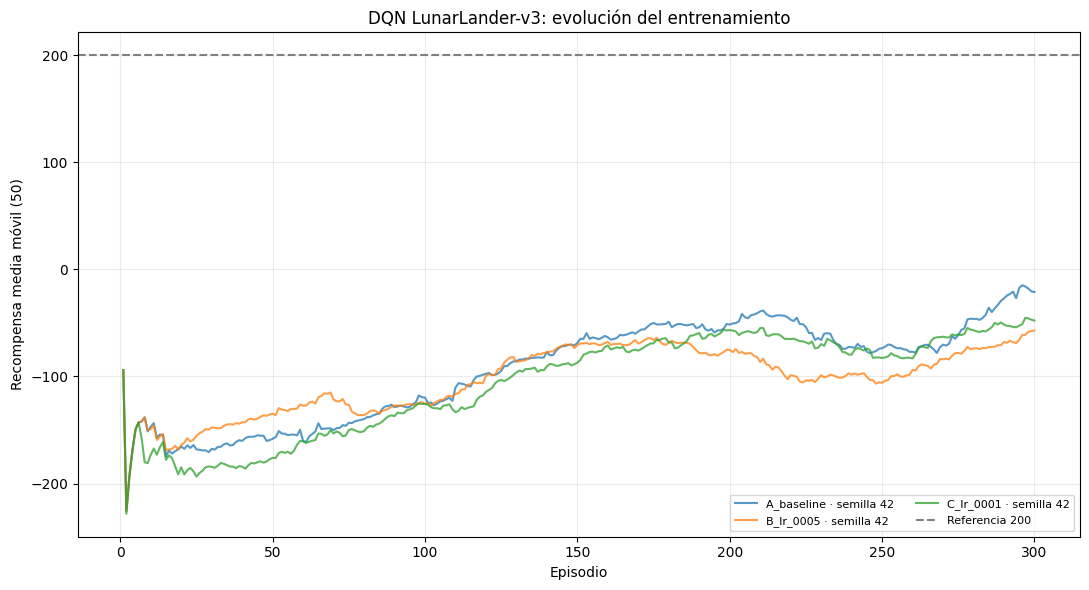

In [ ]:
histories=pd.concat([pd.read_csv(p) for p in sorted(OUT.glob('historial_*_seed*.csv'))],ignore_index=True)
plt.figure(figsize=(11,6))
for (name,seed),g in histories.groupby(['experimento','semilla']):
    g=g.sort_values('episodio')
    smooth=g.recompensa.rolling(50,min_periods=1).mean()
    plt.plot(g.episodio,smooth,label=f'{name} · semilla {seed}',alpha=.75)
plt.axhline(200,linestyle='--',color='gray',label='Referencia 200')
plt.xlabel('Episodio');plt.ylabel('Recompensa media móvil (50)')
plt.title('DQN LunarLander-v3: evolución del entrenamiento')
plt.legend(fontsize=8,ncol=2);plt.grid(alpha=.25);plt.tight_layout()
plt.savefig(OUT/'curvas_entrenamiento.png',dpi=180)
plt.show()

<Figure size 900x500 with 0 Axes>

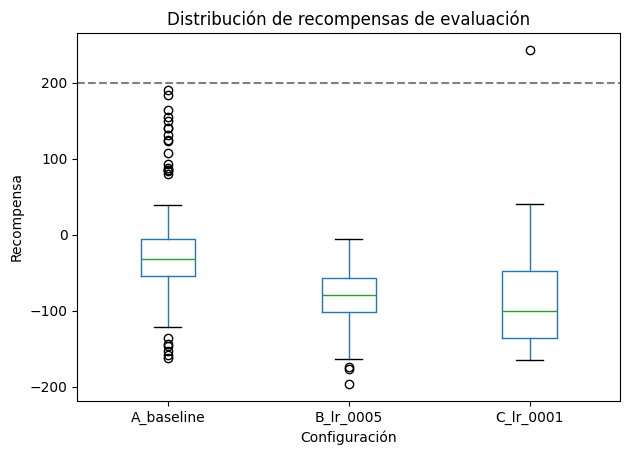

In [ ]:
eval_paths=sorted(OUT.glob('evaluacion_*_seed*.csv'))
evals=pd.concat([pd.read_csv(p) for p in eval_paths],ignore_index=True)
plt.figure(figsize=(9,5))
evals.boxplot(column='recompensa',by='experimento',grid=False)
plt.suptitle('');plt.title('Distribución de recompensas de evaluación')
plt.ylabel('Recompensa');plt.xlabel('Configuración')
plt.axhline(200,linestyle='--',color='gray');plt.tight_layout()
plt.savefig(OUT/'distribucion_evaluacion.png',dpi=180)
plt.show()

## 6. Entrenamiento ampliado, validación y análisis experimental del agente DQN

**Universidad de La Sabana — Maestría en Inteligencia Artificial**  
**Actividad:** Taller 2 — Deep Q-Network en Gymnasium  
**Ambiente:** `LunarLander-v3`  
**Responsable:** Persona 3 — Entrenamiento y experimentación

### 6.1 Objetivo experimental

Evaluar el efecto del número de episodios de entrenamiento y la variabilidad asociada a las semillas aleatorias sobre el desempeño de un agente Deep Q-Network (DQN) en el entorno `LunarLander-v3`.

Se busca determinar si un mayor presupuesto de entrenamiento permite desarrollar una política de control más eficaz para estabilizar y aterrizar la nave, considerando tanto las recompensas acumuladas como la consistencia de los resultados.

### 6.2 Metodología de entrenamiento

La experimentación se desarrolló en dos fases:

**Fase I — Exploración de hiperparámetros**

Se entrenaron tres configuraciones DQN durante 300 episodios, manteniendo constante la arquitectura neuronal y modificando exclusivamente la tasa de aprendizaje (*learning rate*).

| Configuración | Learning rate | Episodios | Semilla |
|---|---:|---:|---:|
| A — Baseline | 0,001 | 300 | 42 |
| B | 0,0005 | 300 | 42 |
| C | 0,0001 | 300 | 42 |

**Fase II — Entrenamiento ampliado**

Se seleccionó la configuración A, que obtuvo la mejor recompensa media durante la evaluación exploratoria.

Posteriormente, se entrenaron tres agentes independientes durante 1.000 episodios cada uno, utilizando las semillas 42, 123 y 2026.

Este diseño permitió analizar la reproducibilidad del aprendizaje y comparar el desempeño bajo diferentes inicializaciones aleatorias.

### 6.3 Arquitectura neuronal e hiperparámetros

Se utilizó una red neuronal multicapa (*Multilayer Perceptron*, MLP) implementada en PyTorch:

**Entrada (8) → Capa oculta (128, ReLU) → Capa oculta (128, ReLU) → Salida (4)**

Las ocho entradas corresponden a las variables de estado del entorno, mientras que las cuatro salidas representan los valores Q asociados a las acciones discretas disponibles.

| Hiperparámetro | Valor |
|---|---|
| Algoritmo | Deep Q-Network |
| Episodios exploratorios | 300 |
| Episodios por entrenamiento ampliado | 1.000 |
| Learning rate seleccionado | 0,001 |
| Factor de descuento γ | 0,99 |
| Epsilon inicial | 1,0 |
| Epsilon mínimo | 0,01 |
| Decaimiento de epsilon | 0,995 por episodio |
| Replay Buffer | 100.000 experiencias |
| Batch size | 64 |
| Actualización Target Network | Cada 10 episodios |
| Optimizador | Adam |
| Función de pérdida | MSE |
| Semillas de entrenamiento ampliado | 42, 123, 2026 |

El entrenamiento utilizó una estrategia de exploración ε-greedy, un búfer de repetición de experiencias y una red objetivo para estabilizar las actualizaciones de los valores Q.

Cada episodio finalizó cuando el entorno devolvió `terminated=True` o `truncated=True`.

En la actualización de Bellman, la implementación distingue las terminaciones reales de las truncaciones temporales, conservando el valor futuro estimado cuando corresponde.

### 6.4 Resultados de la fase exploratoria

| Configuración | Recompensa media de evaluación | Desviación estándar |
|---|---:|---:|
| A — 0,001 | **−16,97** | 75,34 |
| B — 0,0005 | −81,16 | 34,33 |
| C — 0,0001 | −85,46 | 63,03 |

La configuración A presentó el mejor desempeño medio tras 300 episodios. No obstante, las recompensas negativas evidenciaron que el presupuesto inicial de entrenamiento era insuficiente para obtener una política consistentemente eficaz.

Por esta razón, se seleccionó A para ampliar el entrenamiento y estudiar la evolución del aprendizaje.

### 6.5 Resultados del entrenamiento ampliado

Se realizaron tres entrenamientos independientes de 1.000 episodios cada uno, seguidos de 100 episodios de evaluación por agente, utilizando las mismas semillas de evaluación y una política greedy.

| Semilla | Recompensa media | Desviación estándar | Evaluaciones ≥ 200 |
|---|---:|---:|---:|
| 42 | 206,39 | 116,31 | 78 % |
| 123 | 205,87 | 104,05 | 74 % |
| 2026 | **238,15** | **67,11** | **84 %** |

**Recompensa media entre los tres agentes: 216,80 puntos.**

El agente entrenado con la semilla 2026 obtuvo el mejor desempeño observado, con mayor recompensa media y menor dispersión de resultados.

Sin embargo, estos resultados no implican que dicha semilla sea universalmente superior: cada entrenamiento corresponde a una trayectoria de aprendizaje diferente.

### 6.6 Comparación del presupuesto de entrenamiento

Para la configuración A con semilla 42:

- **300 episodios:** recompensa media de −16,97.
- **1.000 episodios:** recompensa media de 206,39.
- **Diferencia observada:** +223,36 puntos.

El aumento del presupuesto de entrenamiento estuvo asociado con una mejora sustancial del desempeño en la evaluación.

Es importante señalar que ambos agentes fueron entrenados independientemente desde cero. Por tanto, no se trata de una continuación directa de los pesos del modelo de 300 episodios.

### 6.7 Evaluación de reproducibilidad y estabilidad

La utilización de tres semillas permitió comprobar que la configuración seleccionada alcanzó recompensas medias superiores a 200 en las tres ejecuciones.

No obstante, las diferencias entre las desviaciones estándar indican que el desempeño continúa siendo sensible a las condiciones aleatorias del entrenamiento y de la evaluación.

La proporción de evaluaciones con recompensa igual o superior a 200 se utilizó como indicador de desempeño. Este criterio no debe confundirse con una tasa de aterrizajes exitosos, ya que no se registró directamente dicha condición.

### 6.8 Dificultades técnicas y estrategias de solución

Durante el desarrollo experimental se identificaron los siguientes retos:

1. **Tiempo computacional:** los entrenamientos ampliados requirieron períodos significativamente mayores que los ensayos iniciales. Se adoptó una estrategia por fases para seleccionar primero una configuración prometedora.
2. **Persistencia de modelos:** se implementó el almacenamiento de pesos y resultados en Google Drive para evitar la pérdida de los modelos entrenados.
3. **Error en la evaluación:** se detectó una función de evaluación no definida después de completar un entrenamiento de 1.000 episodios. La conservación previa de los pesos permitió recuperar y evaluar el agente sin repetir el entrenamiento.
4. **Variabilidad del aprendizaje:** se observaron diferencias entre las recompensas de entrenamiento y evaluación, así como entre las semillas utilizadas, lo que motivó un análisis adicional de estabilidad.

### 6.9 Conclusión preliminar

Los resultados respaldan la hipótesis de que un mayor presupuesto de entrenamiento puede mejorar significativamente el desempeño de un agente DQN en `LunarLander-v3`.

La configuración seleccionada alcanzó recompensas medias superiores a 200 en tres entrenamientos independientes, lo que constituye evidencia favorable de aprendizaje de una política de control eficaz.

Sin embargo, la variabilidad observada y el número limitado de semillas restringen el alcance de las conclusiones. La evaluación de aterrizajes exitosos, la comparación con políticas de referencia y el análisis de más inicializaciones permitirían fortalecer la validez experimental.

### 6.10 Evidencia computacional

Las siguientes celdas contienen el respaldo de los experimentos, la evaluación de los modelos entrenados, el análisis estadístico y la generación de gráficas comparativas.

Los modelos y resultados se almacenan en Google Drive para preservar su trazabilidad y facilitar su posterior publicación en GitHub.

In [ ]:

# ============================================================
# SECCIÓN 9 - RESPALDO DEL EXPERIMENTO DE 300 EPISODIOS
# ============================================================

from pathlib import Path
import pandas as pd

CARPETA_300 = OUT / "experimento_300"
CARPETA_300.mkdir(parents=True, exist_ok=True)

# Guardar copia de los resultados en memoria
if "summaries" in globals():
    pd.DataFrame(summaries).to_csv(
        CARPETA_300 / "resumen_300.csv",
        index=False
    )

if "all_histories" in globals():
    pd.concat(all_histories, ignore_index=True).to_csv(
        CARPETA_300 / "historial_300.csv",
        index=False
    )

if "all_evaluations" in globals():
    pd.concat(all_evaluations, ignore_index=True).to_csv(
        CARPETA_300 / "evaluaciones_300.csv",
        index=False
    )

print("Respaldo de resultados de 300 episodios finalizado.")
print("Carpeta:", CARPETA_300)


Respaldo de resultados de 300 episodios finalizado.
Carpeta: /content/drive/MyDrive/Taller_2_DQN_Adrian/experimento_300


**Nota.** El registro que aparece bajo la siguiente celda es el original de Colab. Allí el entrenamiento se hizo en dos corridas: primero la semilla 42 y después las semillas 123 y 2026.

In [ ]:

# ============================================================
# SECCIÓN 10 - ENTRENAMIENTO DQN: 3.000 EPISODIOS TOTALES
# ============================================================

import pandas as pd
import numpy as np
import time
import torch
from pathlib import Path

# Carpeta independiente para no mezclar experimentos
OUT_3000 = OUT / "experimento_3000"
OUT_3000.mkdir(parents=True, exist_ok=True)

# Configuración ganadora del ensayo preliminar
CONFIG_FINAL = {
    "name": "A_baseline_1000",
    "lr": 0.001
}

# Tres entrenamientos independientes
SEMILLAS_3000 = [42, 123, 2026]
EPISODIOS_POR_SEMILLA = 1000

# Evaluación común para los tres modelos
SEMILLAS_EVALUACION = list(range(10000, 10100))

resultados_3000 = []
historiales_3000 = []
evaluaciones_3000 = []

print("=" * 65)
print("EXPERIMENTO DQN - LUNARLANDER-v3")
print("3 semillas x 1.000 episodios = 3.000 episodios")
print("=" * 65)

for indice, semilla in enumerate(SEMILLAS_3000, start=1):

    nombre = f"{CONFIG_FINAL['name']}_seed{semilla}"

    print(f"\nENTRENAMIENTO {indice}/3")
    print("Modelo:", nombre)

    inicio = time.time()

    modelo, historial, duracion = train_experiment(
        name=CONFIG_FINAL["name"],
        seed=semilla,
        episodes=EPISODIOS_POR_SEMILLA,
        lr=CONFIG_FINAL["lr"],
        log_every=50
    )

    # Guardar pesos del modelo al terminar cada semilla
    ruta_modelo = OUT_3000 / f"modelo_seed{semilla}.pth"

    torch.save(
        modelo.state_dict(),
        ruta_modelo
    )

    # Guardar historial individual
    historial.to_csv(
        OUT_3000 / f"historial_seed{semilla}.csv",
        index=False
    )

    historiales_3000.append(historial)

    # Evaluación: misma metodología del notebook original
    scores = evaluate_model(
        modelo,
        SEMILLAS_EVALUACION
    )

    scores = np.asarray(scores)

    evaluacion = pd.DataFrame({
        "experimento": nombre,
        "semilla_entrenamiento": semilla,
        "semilla_evaluacion": SEMILLAS_EVALUACION,
        "recompensa": scores
    })

    evaluaciones_3000.append(evaluacion)

    evaluacion.to_csv(
        OUT_3000 / f"evaluacion_seed{semilla}.csv",
        index=False
    )

    resumen = {
        "experimento": nombre,
        "semilla": semilla,
        "learning_rate": CONFIG_FINAL["lr"],
        "episodios": EPISODIOS_POR_SEMILLA,
        "media_evaluacion": float(scores.mean()),
        "desviacion_evaluacion": float(scores.std()),
        "proporcion_ge_200": float(np.mean(scores >= 200)),
        "media_ultimos_100_entrenamiento":
            float(historial["recompensa"].tail(100).mean()),
        "duracion_segundos": duracion
    }

    resultados_3000.append(resumen)

    # Guardar resumen incremental para evitar perder resultados
    pd.DataFrame(resultados_3000).to_csv(
        OUT_3000 / "resumen_3000.csv",
        index=False
    )

    print("\nRESULTADO DE LA SEMILLA:", semilla)
    print("Recompensa media:", round(scores.mean(), 2))
    print("Desviación:", round(scores.std(), 2))
    print("Proporción recompensa >= 200:",
          round(np.mean(scores >= 200), 3))
    print("Tiempo:", round(duracion / 60, 2), "minutos")
    print("Modelo guardado:", ruta_modelo)

print("\nTODOS LOS ENTRENAMIENTOS FINALIZADOS")


EXPERIMENTO DQN - LUNARLANDER-v3
3 semillas x 1.000 episodios = 3.000 episodios

ENTRENAMIENTO 1/3
Modelo: A_baseline_1000_seed42
A_baseline_1000 semilla=42 episodio=50/1000 promedio_ultimos_25=-148.5 epsilon=0.778 tiempo=10s
A_baseline_1000 semilla=42 episodio=100/1000 promedio_ultimos_25=-101.4 epsilon=0.606 tiempo=23s
A_baseline_1000 semilla=42 episodio=150/1000 promedio_ultimos_25=-49.5 epsilon=0.471 tiempo=41s
A_baseline_1000 semilla=42 episodio=200/1000 promedio_ultimos_25=-52.7 epsilon=0.367 tiempo=106s
A_baseline_1000 semilla=42 episodio=250/1000 promedio_ultimos_25=-92.1 epsilon=0.286 tiempo=207s
A_baseline_1000 semilla=42 episodio=300/1000 promedio_ultimos_25=-11.5 epsilon=0.222 tiempo=320s
A_baseline_1000 semilla=42 episodio=350/1000 promedio_ultimos_25=-10.4 epsilon=0.173 tiempo=436s
A_baseline_1000 semilla=42 episodio=400/1000 promedio_ultimos_25=4.3 epsilon=0.135 tiempo=548s
A_baseline_1000 semilla=42 episodio=450/1000 promedio_ultimos_25=-10.6 epsilon=0.105 tiempo=678s
A


ENTRENANDO MODELO CON SEMILLA 123
A_baseline_1000 semilla=123 episodio=50/1000 promedio_ultimos_25=-139.4 epsilon=0.778 tiempo=11s
A_baseline_1000 semilla=123 episodio=100/1000 promedio_ultimos_25=-85.0 epsilon=0.606 tiempo=26s
A_baseline_1000 semilla=123 episodio=150/1000 promedio_ultimos_25=-52.2 epsilon=0.471 tiempo=47s
A_baseline_1000 semilla=123 episodio=200/1000 promedio_ultimos_25=-113.4 epsilon=0.367 tiempo=119s
A_baseline_1000 semilla=123 episodio=250/1000 promedio_ultimos_25=-56.8 epsilon=0.286 tiempo=232s
A_baseline_1000 semilla=123 episodio=300/1000 promedio_ultimos_25=-49.9 epsilon=0.222 tiempo=361s
A_baseline_1000 semilla=123 episodio=350/1000 promedio_ultimos_25=-46.8 epsilon=0.173 tiempo=484s
A_baseline_1000 semilla=123 episodio=400/1000 promedio_ultimos_25=-25.5 epsilon=0.135 tiempo=638s
A_baseline_1000 semilla=123 episodio=450/1000 promedio_ultimos_25=102.2 epsilon=0.105 tiempo=753s
A_baseline_1000 semilla=123 episodio=500/1000 promedio_ultimos_25=190.3 epsilon=0.082

In [ ]:

# ==========================================================
# SECCIÓN 12 - PREPARACIÓN DEL ANÁLISIS FINAL
# ==========================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import shutil
import zipfile

BASE = OUT   # la carpeta definida al inicio del notebook
P300 = BASE / "experimento_300"
P1000 = BASE / "experimento_3000"
FIG = BASE / "figuras_finales"
FIG.mkdir(parents=True, exist_ok=True)

SEMILLAS = [42, 123, 2026]

# Verificación: nunca sobrescribimos modelos
for semilla in SEMILLAS:
    ruta = P1000 / f"modelo_seed{semilla}.pth"
    assert ruta.exists(), f"Falta el modelo: {ruta}"
    print(f"Modelo {semilla}: protegido")

print("\nCarpeta de figuras:", FIG)


Modelo 42: protegido
Modelo 123: protegido
Modelo 2026: protegido

Carpeta de figuras: /content/drive/MyDrive/Taller_2_DQN_Adrian/figuras_finales


In [ ]:

# ==========================================================
# SECCIÓN 13 - RESULTADOS DE LOS TRES AGENTES
# ==========================================================

evaluaciones = []
resumen = []

for semilla in SEMILLAS:
    ruta = P1000 / f"evaluacion_seed{semilla}.csv"
    assert ruta.exists(), f"No se encontró {ruta}"

    df = pd.read_csv(ruta)
    recompensas = df["recompensa"].to_numpy(dtype=float)

    df["semilla_entrenamiento"] = semilla
    evaluaciones.append(df)

    resumen.append({
        "semilla": semilla,
        "episodios": 1000,
        "n_evaluaciones": len(recompensas),
        "media": recompensas.mean(),
        "desviacion": recompensas.std(ddof=0),
        "mediana": np.median(recompensas),
        "minimo": recompensas.min(),
        "maximo": recompensas.max(),
        "proporcion_ge_200": np.mean(recompensas >= 200)
    })

df_evaluaciones = pd.concat(
    evaluaciones, ignore_index=True
)

df_resumen = pd.DataFrame(resumen)

display(df_resumen.round(3))

df_resumen.to_csv(
    BASE / "resumen_final_modelos.csv",
    index=False
)

print("Tabla final guardada correctamente.")


,semilla,episodios,n_evaluaciones,media,desviacion,mediana,minimo,maximo,proporcion_ge_200
0,42,1000,100,206.391,116.307,255.414,-147.107,304.223,0.78
1,123,1000,100,205.866,104.049,254.266,-169.654,309.150,0.74
2,2026,1000,100,238.152,67.114,259.252,-16.368,308.031,0.84


Tabla final guardada correctamente.


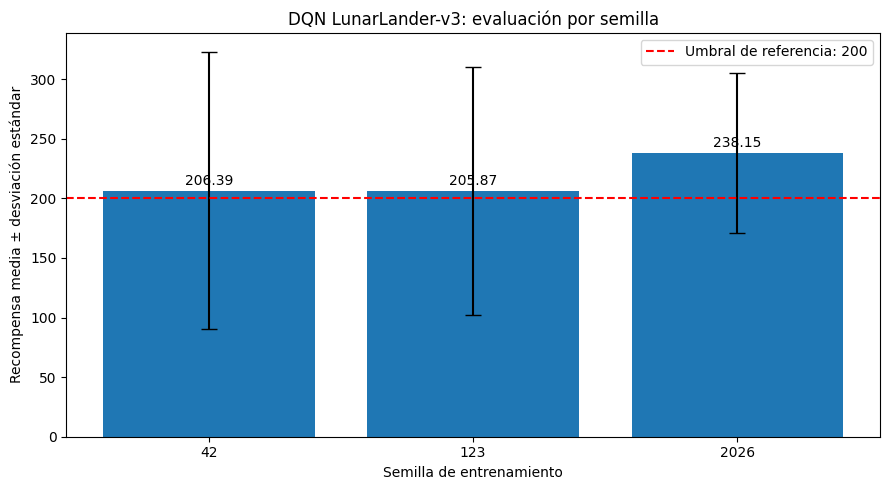

In [ ]:

# ==========================================================
# SECCIÓN 14 - COMPARACIÓN DE RECOMPENSAS
# ==========================================================

fig, ax = plt.subplots(figsize=(9, 5))

etiquetas = [str(s) for s in df_resumen["semilla"]]

barras = ax.bar(
    etiquetas,
    df_resumen["media"],
    yerr=df_resumen["desviacion"],
    capsize=6
)

ax.axhline(
    200,
    color="red",
    linestyle="--",
    label="Umbral de referencia: 200"
)

ax.set_title(
    "DQN LunarLander-v3: evaluación por semilla"
)
ax.set_xlabel("Semilla de entrenamiento")
ax.set_ylabel("Recompensa media ± desviación estándar")
ax.legend()

for barra, valor in zip(barras, df_resumen["media"]):
    ax.text(
        barra.get_x() + barra.get_width()/2,
        valor + 5,
        f"{valor:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    FIG / "01_comparacion_modelos.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


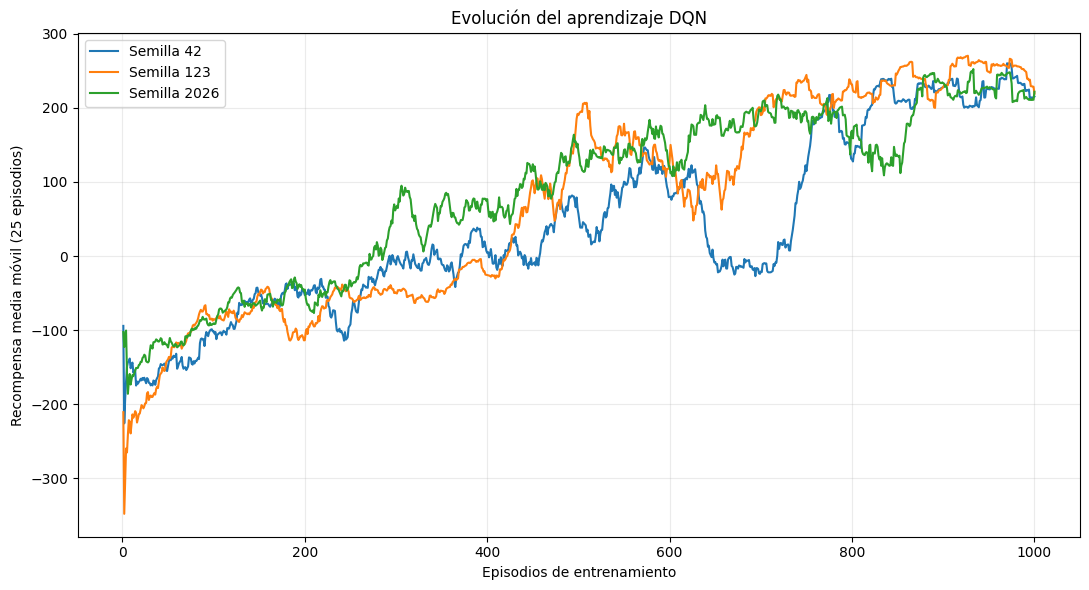

In [ ]:

# ==========================================================
# SECCIÓN 15 - CURVAS DE APRENDIZAJE
# ==========================================================

fig, ax = plt.subplots(figsize=(11, 6))

historiales = []

for semilla in SEMILLAS:
    ruta = P1000 / f"historial_seed{semilla}.csv"

    if not ruta.exists():
        print(f"Sin historial guardado para semilla {semilla}")
        continue

    df = pd.read_csv(ruta)

    if "episodio" not in df.columns or "recompensa" not in df.columns:
        print(f"Columnas inesperadas en {ruta.name}")
        continue

    df["semilla"] = semilla
    historiales.append(df)

    df = df.sort_values("episodio")
    media_movil = (
        df["recompensa"]
        .rolling(window=25, min_periods=1)
        .mean()
    )

    ax.plot(
        df["episodio"],
        media_movil,
        label=f"Semilla {semilla}"
    )

if historiales:
    ax.set_title("Evolución del aprendizaje DQN")
    ax.set_xlabel("Episodios de entrenamiento")
    ax.set_ylabel("Recompensa media móvil (25 episodios)")
    ax.legend()
    ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.savefig(
        FIG / "02_curvas_aprendizaje.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
else:
    plt.close(fig)
    print("No hay historiales CSV disponibles.")


,episodios,semilla,learning_rate,recompensa_media,desviacion
0,300,42,0.0,-16.97,75.34
1,1000,42,0.0,206.39,116.31


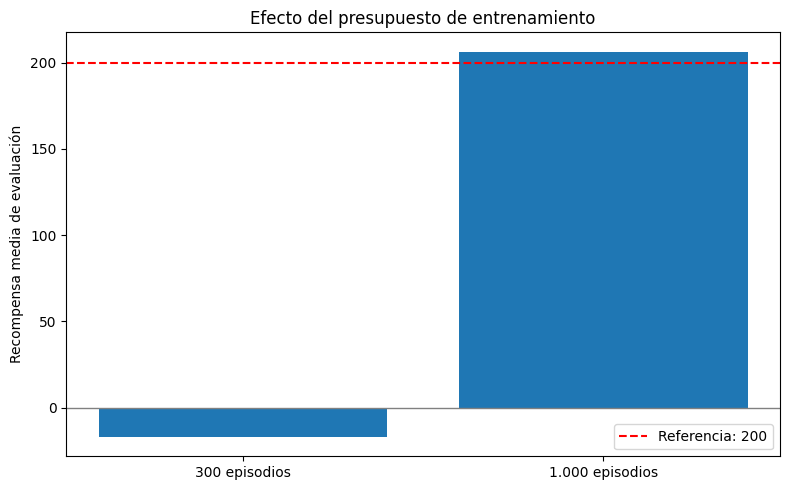

Mejora observada: 223.36 puntos
Fuente del resultado de 300 episodios: CSV original


In [ ]:

# ==========================================================
# SECCIÓN 16 - EFECTO DEL NÚMERO DE EPISODIOS
# ==========================================================

ruta_300 = P300 / "evaluaciones_300.csv"

media_300 = -16.97
desv_300 = 75.34
fuente_300 = "Valores registrados en la ejecución original"

# Si está disponible el CSV, recuperamos los valores exactos
if ruta_300.exists():
    d300 = pd.read_csv(ruta_300)

    if {"experimento", "recompensa"}.issubset(d300.columns):
        d300 = d300[d300["experimento"] == "A_baseline"]

    if "recompensa" in d300.columns and len(d300) > 0:
        media_300 = d300["recompensa"].mean()
        desv_300 = d300["recompensa"].std(ddof=0)
        fuente_300 = "CSV original"

fila_1000 = df_resumen[df_resumen["semilla"] == 42].iloc[0]
media_1000 = fila_1000["media"]

comparacion = pd.DataFrame({
    "episodios": [300, 1000],
    "semilla": [42, 42],
    "learning_rate": [0.001, 0.001],
    "recompensa_media": [media_300, media_1000],
    "desviacion": [desv_300, fila_1000["desviacion"]]
})

display(comparacion.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    ["300 episodios", "1.000 episodios"],
    comparacion["recompensa_media"]
)
ax.axhline(0, color="gray", linewidth=1)
ax.axhline(200, color="red", linestyle="--",
           label="Referencia: 200")
ax.set_ylabel("Recompensa media de evaluación")
ax.set_title("Efecto del presupuesto de entrenamiento")
ax.legend()

plt.tight_layout()
plt.savefig(FIG / "03_comparacion_300_1000.png", dpi=200)
plt.show()

print("Mejora observada:",
      round(media_1000 - media_300, 2), "puntos")
print("Fuente del resultado de 300 episodios:", fuente_300)


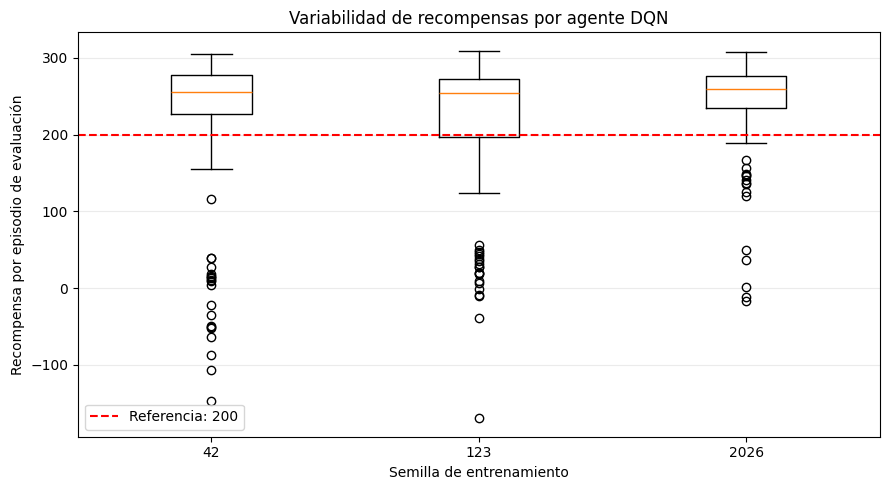

Proporción de evaluaciones con recompensa >= 200
Semilla 42: 78.0%
Semilla 123: 74.0%
Semilla 2026: 84.0%


In [ ]:

# ==========================================================
# SECCIÓN 17 - DISTRIBUCIÓN DE RESULTADOS
# ==========================================================

datos = [
    df_evaluaciones.loc[
        df_evaluaciones["semilla_entrenamiento"] == s,
        "recompensa"
    ].to_numpy()
    for s in SEMILLAS
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(datos, tick_labels=[str(s) for s in SEMILLAS])
ax.axhline(
    200,
    linestyle="--",
    color="red",
    label="Referencia: 200"
)

ax.set_title("Variabilidad de recompensas por agente DQN")
ax.set_xlabel("Semilla de entrenamiento")
ax.set_ylabel("Recompensa por episodio de evaluación")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    FIG / "04_distribucion_recompensas.png",
    dpi=200
)
plt.show()

print("Proporción de evaluaciones con recompensa >= 200")

for s, valores in zip(SEMILLAS, datos):
    print(
        f"Semilla {s}: "
        f"{np.mean(valores >= 200)*100:.1f}%"
    )


In [ ]:

# ==========================================================
# SECCIÓN 18 - ANÁLISIS ESTADÍSTICO
# ==========================================================

rng = np.random.default_rng(2026)

def bootstrap_media(valores, repeticiones=5000):
    valores = np.asarray(valores, dtype=float)
    n = len(valores)

    indices = rng.integers(
        0, n, size=(repeticiones, n)
    )

    medias = valores[indices].mean(axis=1)

    return np.percentile(medias, [2.5, 97.5])

intervalos = []

for semilla, valores in zip(SEMILLAS, datos):
    inferior, superior = bootstrap_media(valores)

    intervalos.append({
        "semilla": semilla,
        "media": valores.mean(),
        "IC95_inferior": inferior,
        "IC95_superior": superior,
        "n": len(valores)
    })

df_intervalos = pd.DataFrame(intervalos)

display(df_intervalos.round(2))

df_intervalos.to_csv(
    BASE / "intervalos_confianza.csv",
    index=False
)


,semilla,media,IC95_inferior,IC95_superior,n
0,42,206.39,183.02,228.36,100
1,123,205.87,185.31,225.38,100
2,2026,238.15,224.30,250.31,100


In [ ]:

# ==========================================================
# SECCIÓN 19 - SELECCIÓN DEL MEJOR AGENTE
# ==========================================================

mejor = df_resumen.loc[df_resumen["media"].idxmax()]
mejor_semilla = int(mejor["semilla"])

ruta_mejor = P1000 / f"modelo_seed{mejor_semilla}.pth"

assert ruta_mejor.exists(), "No se encontró el mejor modelo"

print("=" * 55)
print("MODELO DQN SELECCIONADO")
print("=" * 55)
print("Ambiente: LunarLander-v3")
print("Algoritmo: Deep Q-Network")
print("Arquitectura: 8 -> 128 -> 128 -> 4")
print("Learning rate: 0.001")
print("Episodios: 1000")
print("Semilla:", mejor_semilla)
print("Recompensa media:", round(mejor["media"], 2))
print("Desviación:", round(mejor["desviacion"], 2))
print("Proporción >= 200:",
      round(mejor["proporcion_ge_200"] * 100, 1), "%")
print("Modelo:", ruta_mejor)

# Copiar el mejor modelo sin modificar el original
shutil.copy2(
    ruta_mejor,
    BASE / "mejor_modelo_dqn.pth"
)

print("\nCopia del mejor modelo creada correctamente.")


MODELO DQN SELECCIONADO
Ambiente: LunarLander-v3
Algoritmo: Deep Q-Network
Arquitectura: 8 -> 128 -> 128 -> 4
Learning rate: 0.001
Episodios: 1000
Semilla: 2026
Recompensa media: 238.15
Desviación: 67.11
Proporción >= 200: 84.0 %
Modelo: /content/drive/MyDrive/Taller_2_DQN_Adrian/experimento_3000/modelo_seed2026.pth

Copia del mejor modelo creada correctamente.


In [ ]:

# ==========================================================
# SECCIÓN 20 - INFORME DE ENTRENAMIENTO Y EXPERIMENTACIÓN
# ==========================================================

media_global = df_resumen["media"].mean()
exitos_referencia = int(
    (df_evaluaciones["recompensa"] >= 200).sum()
)
total_evaluaciones = len(df_evaluaciones)

filas = "\n".join(
    f"| {int(r.semilla)} | {r.media:.2f} | "
    f"{r.desviacion:.2f} | "
    f"{100*r.proporcion_ge_200:.1f}% |"
    for r in df_resumen.itertuples()
)

informe = f"""# Persona 3 — Entrenamiento y experimentación DQN

## Objetivo

Entrenar y comparar agentes Deep Q-Network en el entorno
LunarLander-v3, evaluando el efecto de los hiperparámetros,
el número de episodios y la variabilidad entre semillas.

## Diseño experimental

Se realizó una fase exploratoria con tres tasas de aprendizaje:
0.001, 0.0005 y 0.0001, durante 300 episodios con semilla 42.

Posteriormente se seleccionó la configuración 0.001
para entrenar tres agentes independientes durante
1.000 episodios cada uno, con semillas 42, 123 y 2026.

Cada agente se evaluó mediante 100 episodios con semillas
comunes, utilizando una política greedy sin exploración.

## Resultados de evaluación

| Semilla | Media | Desviación estándar | Recompensas >= 200 |
|---|---:|---:|---:|
{filas}

La recompensa media entre las tres ejecuciones fue
{media_global:.2f} puntos.

De {total_evaluaciones} episodios de evaluación,
{exitos_referencia} alcanzaron una recompensa >= 200.

## Comparación de 300 y 1.000 episodios

Con semilla 42 y learning rate 0.001:

- 300 episodios: recompensa media {media_300:.2f}.
- 1.000 episodios: recompensa media {media_1000:.2f}.
- Diferencia observada: {media_1000-media_300:.2f} puntos.

Los modelos fueron entrenados independientemente desde cero.
Por tanto, la comparación muestra el efecto observado
de dos presupuestos de entrenamiento, no una continuación
del mismo modelo.

## Selección del mejor agente

El mejor modelo según la recompensa media observada
correspondió a la semilla {mejor_semilla}, con una recompensa
de {mejor["media"]:.2f} puntos.

Esta selección es empírica y no demuestra superioridad
universal de una semilla particular.

## Interpretación

Los resultados sugieren que aumentar el presupuesto de
entrenamiento permitió obtener políticas de control
más eficaces en las condiciones evaluadas.

No obstante, las diferencias entre semillas y la dispersión
de recompensas evidencian que el aprendizaje no fue
completamente uniforme.

El umbral de recompensa >= 200 se empleó como indicador
de desempeño; no equivale por sí solo a una medición
directa de aterrizajes exitosos.

## Dificultades técnicas

Durante la ejecución surgió un error por la ausencia
de una función de evaluación. El entrenamiento había
finalizado y los pesos estaban guardados, por lo que
fue posible recuperar el modelo sin repetir el proceso.

También fue necesario administrar el tiempo de cómputo,
separar los experimentos y conservar los resultados
en Google Drive.

## Limitaciones

- Se utilizaron tres semillas de entrenamiento.
- La comparación de tasas de aprendizaje fue exploratoria.
- No se midió directamente el porcentaje de aterrizajes.
- Los intervalos de evaluación no reemplazan una
  evaluación de variabilidad entre múltiples entrenamientos.
- El rendimiento puede cambiar con otros hiperparámetros,
  inicializaciones y condiciones de evaluación.

## Evidencia gráfica

![Comparación de modelos](figuras_finales/01_comparacion_modelos.png)

![Curvas de aprendizaje](figuras_finales/02_curvas_aprendizaje.png)

![Comparación de episodios](figuras_finales/03_comparacion_300_1000.png)

![Distribución de recompensas](figuras_finales/04_distribucion_recompensas.png)
"""

ruta_informe = BASE / "INFORME_PERSONA_3.md"
ruta_informe.write_text(informe, encoding="utf-8")

print("Informe generado:", ruta_informe)
print("\nVista previa:\n")
print(informe[:2500])


Informe generado: /content/drive/MyDrive/Taller_2_DQN_Adrian/INFORME_PERSONA_3.md

Vista previa:

# Persona 3 — Entrenamiento y experimentación DQN

## Objetivo

Entrenar y comparar agentes Deep Q-Network en el entorno
LunarLander-v3, evaluando el efecto de los hiperparámetros,
el número de episodios y la variabilidad entre semillas.

## Diseño experimental

Se realizó una fase exploratoria con tres tasas de aprendizaje:
0.001, 0.0005 y 0.0001, durante 300 episodios con semilla 42.

Posteriormente se seleccionó la configuración 0.001
para entrenar tres agentes independientes durante
1.000 episodios cada uno, con semillas 42, 123 y 2026.

Cada agente se evaluó mediante 100 episodios con semillas
comunes, utilizando una política greedy sin exploración.

## Resultados de evaluación

| Semilla | Media | Desviación estándar | Recompensas >= 200 |
|---|---:|---:|---:|
| 42 | 206.39 | 116.31 | 78.0% |
| 123 | 205.87 | 104.05 | 74.0% |
| 2026 | 238.15 | 67.11 | 84.0% |

La recompensa media ent

In [4]:
# ==========================================================
# SECCIÓN 21 - EXPORTACIÓN FINAL DE RESULTADOS A CSV
# Taller 2 - DQN LunarLander-v3
# Persona 3 - Entrenamiento y experimentación
# ==========================================================

import pandas as pd
from pathlib import Path
# Carpeta donde guardamos los experimentos (la definida al inicio del notebook)
BASE = OUT
CARPETA = BASE / "experimento_3000"

resultados = []

print(f"Buscando archivos de evaluación en: {CARPETA}")

# Recuperar las evaluaciones reales de los tres modelos
for semilla in [42, 123, 2026]:
    archivo = CARPETA / f"evaluacion_seed{semilla}.csv"

    if not archivo.exists():
        print(f"ADVERTENCIA: No existe {archivo.name}")
        continue

    df = pd.read_csv(archivo)
    recompensas = df["recompensa"]

    resultados.append({
        "Ambiente": "LunarLander-v3",
        "Algoritmo": "DQN",
        "Semilla": semilla,
        "Episodios_entrenamiento": 1000,
        "Learning_rate": 0.001,
        "Evaluaciones": len(recompensas),
        "Recompensa_media": round(recompensas.mean(), 2),
        "Desviacion_estandar": round(recompensas.std(ddof=0), 2),
        "Mediana": round(recompensas.median(), 2),
        "Recompensa_minima": round(recompensas.min(), 2),
        "Recompensa_maxima": round(recompensas.max(), 2),
        "Porcentaje_recompensa_200": round(
            (recompensas >= 200).mean() * 100, 2
        )
    })

# Crear tabla consolidada
resultado_final = pd.DataFrame(resultados)

if len(resultado_final) != 3:
    raise ValueError(
        "Faltan evaluaciones. Se esperaban las tres semillas."
    )

print("RESULTADOS FINALES DQN")
display(resultado_final)

# Guardar en Google Drive
ruta_csv = BASE / "resultados_finales_DQN_Persona3.csv"
resultado_final.to_csv(
    ruta_csv,
    index=False,
    encoding="utf-8-sig"
)

print(f"\nCSV guardado en: {ruta_csv}")

# Descargar automáticamente al computador
try:
    from google.colab import files
    files.download(str(ruta_csv))
except ImportError:
    pass   # fuera de Colab el archivo ya quedó en la carpeta de resultados

Buscando archivos de evaluación en: /content/drive/MyDrive/Taller_2_DQN_Adrian/experimento_3000
RESULTADOS FINALES DQN


,Ambiente,Algoritmo,Semilla,Episodios_entrenamiento,Learning_rate,Evaluaciones,Recompensa_media,Desviacion_estandar,Mediana,Recompensa_minima,Recompensa_maxima,Porcentaje_recompensa_200
0,LunarLander-v3,DQN,42,1000,0.001,100,206.39,116.31,255.41,-147.11,304.22,78.0
1,LunarLander-v3,DQN,123,1000,0.001,100,205.87,104.05,254.27,-169.65,309.15,74.0
2,LunarLander-v3,DQN,2026,1000,0.001,100,238.15,67.11,259.25,-16.37,308.03,84.0



CSV guardado en: /content/drive/MyDrive/Taller_2_DQN_Adrian/resultados_finales_DQN_Persona3.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>